Feature Selection

In [10]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np

In [11]:

from pathlib import Path

# Individua automaticamente la cartella del progetto
current_dir = Path.cwd().resolve()

BASE_DIR = next(
    (p for p in (current_dir, *current_dir.parents)
     if (p / "Dati").is_dir() and (p / "03_DashBoard").is_dir()),
    None
)

if BASE_DIR is None:
    raise FileNotFoundError("Cartella principale del progetto non trovata")

DATA_DIR = BASE_DIR / "Dati"
DASHBOARD_DIR = BASE_DIR / "03_DashBoard"
MODEL_DIR = DASHBOARD_DIR / "modello_r_f"


In [12]:
#Creiamo un file_path per semplificare l'accesso al dataframe appena creato in 00_DataExploration

file_path = DATA_DIR / "DataFrame_00.csv"

In [13]:
#Importiamo il dataframe appena creato in 00_DataExploration

df = pd.read_csv(file_path)

In [14]:
#Controlliamo che le modifiche sulle colonne siano avvenute

df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type',
       'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [15]:
#Iniziamo impostando la nostra variabile target

target = 'adr'

#Creiamo una lista di variabili da eliminare

escluse = ['is_canceled', 'reservation_status', 'reservation_status_date',  # Note solo dopo la prenotazione (leakage)
            'assigned_room_type',          # Decisa dall'hotel all'arrivo (leakage)
            'arrival_date_week_number',    # Ridondante con il mese
            'country'                      # 177 categorie, troppa cardinalità
]

#Eliminiamo queste variabili

df = df.drop(columns=escluse)

In [16]:
#Creiamo una lista di varibaili numeriche

numeriche = ['lead_time', 'arrival_date_year', 'arrival_date_day_of_month',
             'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
             'babies', 'is_repeated_guest', 'previous_cancellations',
             'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list',
             'required_car_parking_spaces', 'total_of_special_requests']
 
#Calcolaimo la correlazione fra le varibili numeriche e la nostra variabile target

corr_num = pd.DataFrame({
    'Pearson': df[numeriche].corrwith(df[target], method='pearson'),
    'Spearman': df[numeriche].corrwith(df[target], method='spearman')
})
corr_num = corr_num.loc[corr_num['Spearman'].abs().sort_values(ascending=False).index]
display(corr_num.round(3))

,Pearson,Spearman
children,0.360,0.274
adults,0.276,0.260
arrival_date_year,0.205,0.217
total_of_special_requests,0.188,0.199
previous_cancellations,-0.068,-0.160
previous_bookings_not_canceled,-0.061,-0.124
is_repeated_guest,-0.099,-0.120
stays_in_week_nights,0.051,0.069
days_in_waiting_list,-0.051,-0.048
stays_in_weekend_nights,0.038,0.035


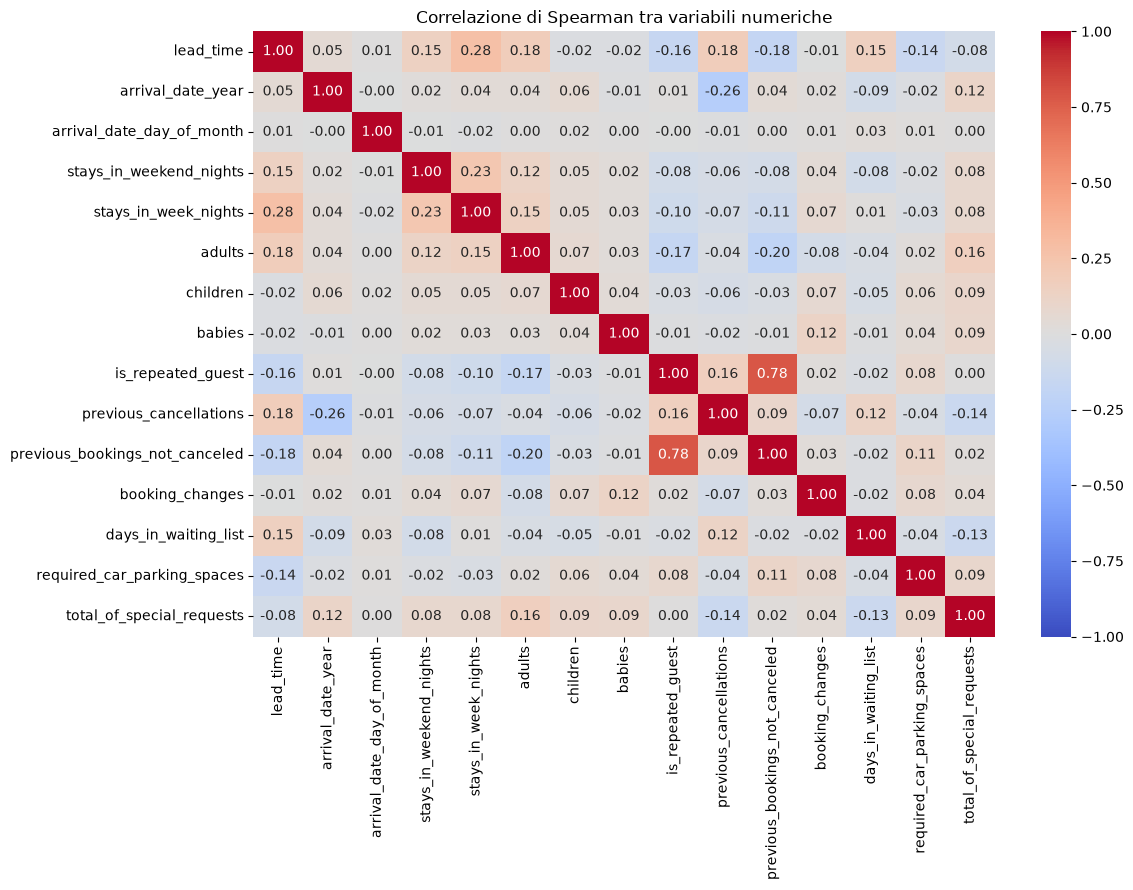

In [17]:
plt.figure(figsize=(12, 9))
sns.heatmap(df[numeriche].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlazione di Spearman tra variabili numeriche')
plt.tight_layout();
plt.show()

In [18]:
#Per qunato riguarda le variabili categoriche Pearson e Spearman non risultano essere indici efficaci per calcolare la correlazione con adr
#L'utilizzo del v-score invece ci richiedeva la divisione in bin della variabile continua adr
#Abbiamo deciso di cercare un nuovo indice di correlazione tra variabile categoriche e continue e abbiamo optato per l'eta quadro

categoriche = ['hotel', 'arrival_date_month', 'meal', 'market_segment',
               'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']

def eta_squared(cat, y):
    g = y.groupby(cat, observed=True)
    ss_between = (g.count() * (g.mean() - y.mean()) ** 2).sum()
    ss_total = ((y - y.mean()) ** 2).sum()
    return ss_between / ss_total

y = df[target]
mask_log = y >= 0
y_log = np.log1p(y[mask_log])

righe = {}
for c in categoriche:
    righe[c] = {
        'n_modalita': df[c].nunique(),
        'eta_sq': eta_squared(df[c], y),
    }

risultati = pd.DataFrame(righe).T
risultati['n_modalita'] = risultati['n_modalita'].astype(int)
     
display(risultati.sort_values('eta_sq', ascending=False).round(3))


,n_modalita,eta_sq
arrival_date_month,12,0.219
reserved_room_type,9,0.216
market_segment,7,0.135
customer_type,4,0.039
distribution_channel,5,0.030
meal,4,0.021
deposit_type,3,0.015
hotel,2,0.006


In [19]:
#Da i risultati dell'eta quadro la variabile hotel risultava poco significativa ma a noi non tornava e quindi abbiamo calcolato media mediana e deviazione std

df.groupby('hotel')[target].agg(['mean','median','std'])

#Il risultato è che molto probabilmente il Resort soffre di alta stagionalità e che spinge la media molto simile a quella del City hotel rendendo la media molto simile

,mean,median,std
hotel,,,
City Hotel,107.168147,100.0,37.052161
Resort Hotel,99.401755,79.3,60.083333


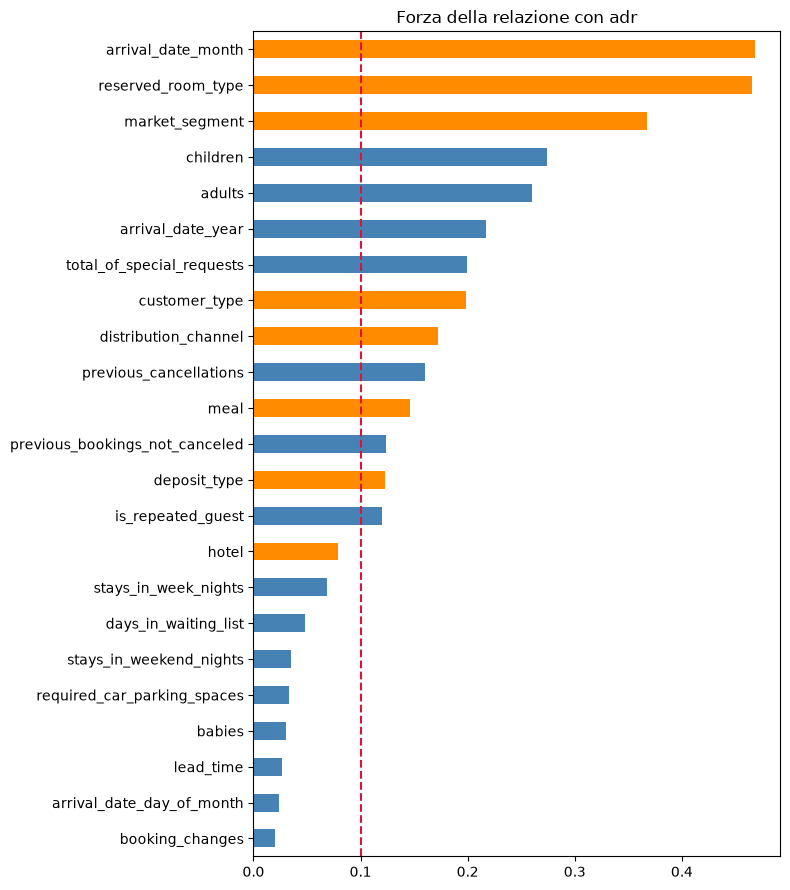

In [20]:
#Qui raffiguriamo la correlazione di tutte le variabili 

spearman_num = df[numeriche].corrwith(df[target], method='spearman').abs()
eta_cat = np.sqrt(risultati['eta_sq'])

tutte = pd.concat([spearman_num, eta_cat]).sort_values()
colori = ['darkorange' if v in eta_cat.index else 'steelblue' for v in tutte.index]

fig, ax = plt.subplots(figsize=(8, 9))
tutte.plot.barh(ax=ax, color=colori)
ax.axvline(0.10, color='crimson', linestyle='--', label='Soglia 0,10')
ax.set_title('Forza della relazione con adr')

from matplotlib.patches import Patch
plt.tight_layout()
plt.show()

In [21]:
#Creiamo una lista di variabili da eliminare

var_to_eliminate = [ 'stays_in_weekend_nights', 'stays_in_week_nights', 'distribution_channel', 'days_in_waiting_list', 'required_car_parking_spaces', 'babies', 'booking_changes']
df = df.drop(var_to_eliminate, axis = 1)

#lead time e hotel abbiamo scelto noi di tenerle

In [22]:
#Salviamo il dataframe appena ottenuto

df.to_csv(DATA_DIR / "DataFrame_01.csv", index=False, encoding="utf-8")

In [23]:
#Serve per creare il file.csv che andrà ad alimentare la dashboard

data_app = df.copy()
 
preferred_columns = [
    "hotel",
    "lead_time",
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month",
    "adults",
    "children",
    "meal",
    "market_segment",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "deposit_type",
    "customer_type",
    "total_of_special_requests",
    "adr"
]
selected_columns = [
    column for column in preferred_columns
    if column in data_app.columns
]
 
if "adr" not in selected_columns:
    raise ValueError("Il dataset deve contenere 'adr' nelle colonne.")
 
data_app = data_app[selected_columns].copy()

data_app = data_app.replace([np.inf, -np.inf], np.nan)

data_app["adr"] = pd.to_numeric(
    data_app["adr"],
    errors="coerce"
)
 
data_app = data_app.dropna(subset=["adr"])
 

data_app.to_csv(
    DASHBOARD_DIR / "DashBoard_data" / "dashboard_data.csv",
    index=False
)
 
print("Dataset salvato con successo.")
print("Shape:", data_app.shape)
print("Colonne:", data_app.columns.tolist())

Dataset salvato con successo.
Shape: (115787, 17)
Colonne: ['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'adults', 'children', 'meal', 'market_segment', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type', 'total_of_special_requests', 'adr']
